<a href="https://colab.research.google.com/github/emirbekk08/data-analysis-practice/blob/main/Practical_Work_5_Classification_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

print("Все библиотеки импортированы!")


Все библиотеки импортированы!


In [6]:

from google.colab import files
uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Размер датасета:", df.shape)
display(df.head())
print("\nНазвания столбцов:")
print(df.columns.tolist())


Saving Churn_Modelling.csv to Churn_Modelling (1).csv
Размер датасета: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Названия столбцов:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


Пропущенные значения:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Количество объектов каждого класса:
Exited
0    7963
1    2037
Name: count, dtype: int64

Доля каждого класса:
Exited
0    0.796
1    0.204
Name: proportion, dtype: float64


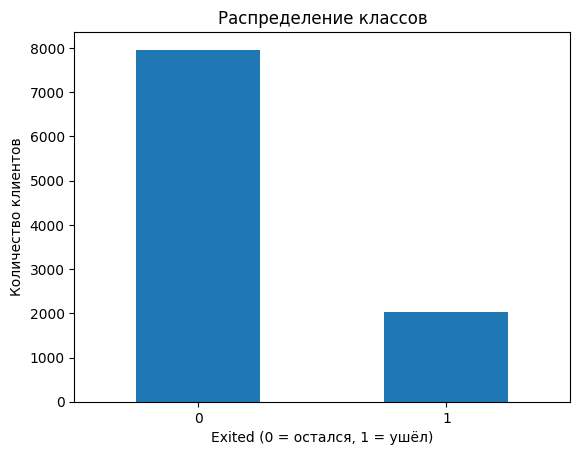

In [7]:

target = "Exited"

print("Пропущенные значения:")
print(df.isnull().sum())

print("\nКоличество объектов каждого класса:")
print(df[target].value_counts())

print("\nДоля каждого класса:")
print(df[target].value_counts(normalize=True).round(3))

df[target].value_counts().sort_index().plot(
    kind="bar", rot=0, title="Распределение классов"
)
plt.xlabel("Exited (0 = остался, 1 = ушёл)")
plt.ylabel("Количество клиентов")
plt.show()


In [8]:

X = df.drop(columns=["Exited", "RowNumber", "CustomerId", "Surname"],
            errors="ignore")
y = df["Exited"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

model.fit(X_train, y_train)

print("Модель успешно обучена!")
print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)


Модель успешно обучена!
Обучающая выборка: (8000, 10)
Тестовая выборка: (2000, 10)


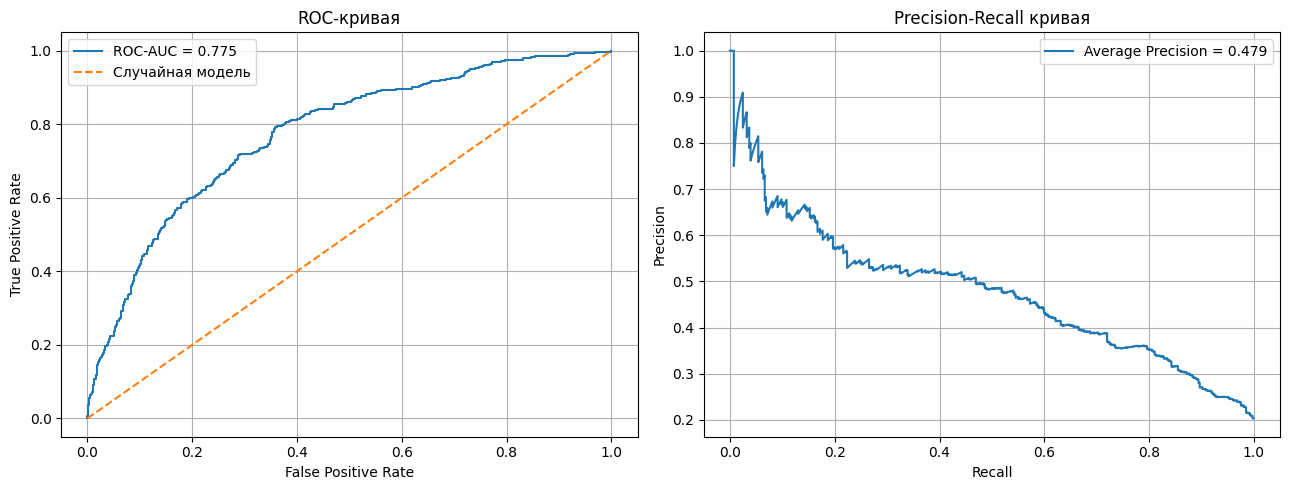

ROC-AUC: 0.7748
Average Precision (PR): 0.4789


In [9]:

y_prob = model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

fpr, tpr, roc_thresholds = roc_curve(y_test, y_prob)
precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test, y_prob
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "--", label="Случайная модель")
axes[0].set_title("ROC-кривая")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(recall_values, precision_values,
             label=f"Average Precision = {pr_auc:.3f}")
axes[1].set_title("Precision-Recall кривая")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"Average Precision (PR): {pr_auc:.4f}")


Лучший порог: 0.17
Минимальная стоимость ошибок: 1003


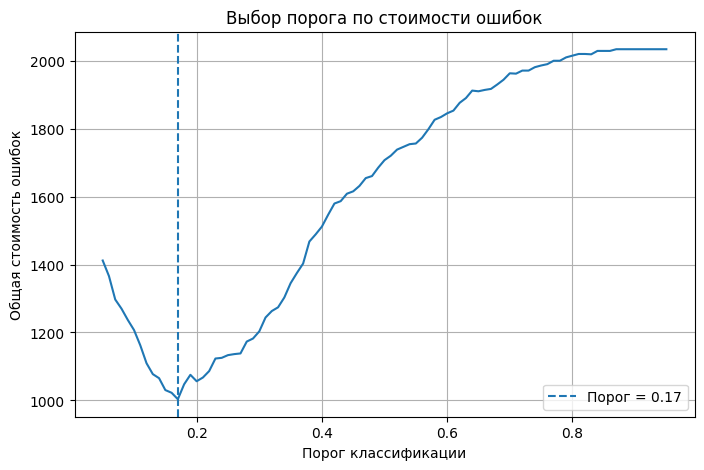

In [10]:

COST_FP = 1
COST_FN = 5

thresholds_to_test = np.linspace(0.05, 0.95, 91)
costs = []

for threshold in thresholds_to_test:
    y_pred_temp = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred_temp, labels=[0, 1]
    ).ravel()

    total_cost = COST_FP * fp + COST_FN * fn
    costs.append(total_cost)

best_index = np.argmin(costs)
best_threshold = thresholds_to_test[best_index]

print("Лучший порог:", round(best_threshold, 3))
print("Минимальная стоимость ошибок:", costs[best_index])

plt.figure(figsize=(8, 5))
plt.plot(thresholds_to_test, costs)
plt.axvline(best_threshold, linestyle="--",
            label=f"Порог = {best_threshold:.2f}")
plt.xlabel("Порог классификации")
plt.ylabel("Общая стоимость ошибок")
plt.title("Выбор порога по стоимости ошибок")
plt.legend()
plt.grid(True)
plt.show()


In [11]:

def evaluate_threshold(y_true, probabilities, threshold, name):
    y_pred = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "Модель": name,
        "Порог": round(threshold, 3),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Стоимость ошибок": COST_FP * fp + COST_FN * fn
    }

results = pd.DataFrame([
    evaluate_threshold(y_test, y_prob, 0.5, "Порог 0.5"),
    evaluate_threshold(
        y_test, y_prob, best_threshold, "Подобранный порог"
    )
])

display(results.round(4))


,Модель,Порог,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Стоимость ошибок
0,Порог 0.5,0.50,0.8080,0.5891,0.1867,0.2836,1540,53,331,76,1708
1,Подобранный порог,0.17,0.6605,0.3528,0.8010,0.4899,995,598,81,326,1003


In [12]:

results.to_csv("threshold_comparison.csv", index=False)

with open("practical_work_5_report.txt", "w", encoding="utf-8") as f:
    f.write("Практическая работа № 5. Вариант B\n")
    f.write(f"ROC-AUC: {roc_auc:.4f}\n")
    f.write(f"Average Precision: {pr_auc:.4f}\n")
    f.write(f"Выбранный порог: {best_threshold:.3f}\n")
    f.write(f"Стоимость FP: {COST_FP}\n")
    f.write(f"Стоимость FN: {COST_FN}\n\n")
    f.write(results.to_string(index=False))

files.download("threshold_comparison.csv")
files.download("practical_work_5_report.txt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Вывод**

В ходе практической работы была обучена модель бинарной классификации Logistic Regression для прогнозирования ухода клиентов банка. Данные были разделены на обучающую и тестовую выборки. Числовые признаки масштабированы, а категориальные закодированы.

Для оценки качества модели были построены ROC- и Precision-Recall кривые, рассчитаны ROC-AUC и Average Precision. Затем были сравнены результаты при стандартном пороге 0,5 и при пороге, подобранном с учётом стоимости ошибок.

Ложноотрицательная ошибка (FN) оценивалась в 5 условных единиц, а ложноположительная (FP) — в 1 условную единицу. Поэтому при выборе порога основное внимание уделялось снижению общей стоимости ошибок, а также анализу Recall, Precision и F1.

Подобранный порог позволяет учитывать цену ошибок предметной задачи, однако его эффективность необходимо оценивать на независимой тестовой выборке. Таким образом, оптимальный порог зависит не только от качества модели, но и от последствий ошибочных прогнозов.